# Session 2 · Supervised Learning

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Hamnakhan123/Diploma-in-Data-Science/blob/main/term-2/03-advanced-data-science-with-python/code/session-02-supervised-learning.ipynb)

Diploma in Data Science · Prepared by **Hamna Zahid Khan**, Junior Lecturer

Run the cells from top to bottom. Every example is self-contained, so you can also run any single cell on its own.

### Example 1 · Basic: linear regression by gradient descent from scratch

epoch   0: MSE =    309,105,228  w =   1211.1  b =   3293.6
epoch   1: MSE =    198,276,947  w =   2180.0  b =   5928.4
epoch   5: MSE =     34,304,713  w =   4468.0  b =  12150.9
epoch  20: MSE =      1,289,812  w =   5999.6  b =  16315.9
epoch  50: MSE =      1,248,891  w =   6055.4  b =  16467.6
epoch 199: MSE =      1,248,891  w =   6055.4  b =  16467.8

learned rule: bill = 1810 + 41.09 x units   (true: 1500 + 42 x units)
predicted bill for 350 units: Rs 16,191


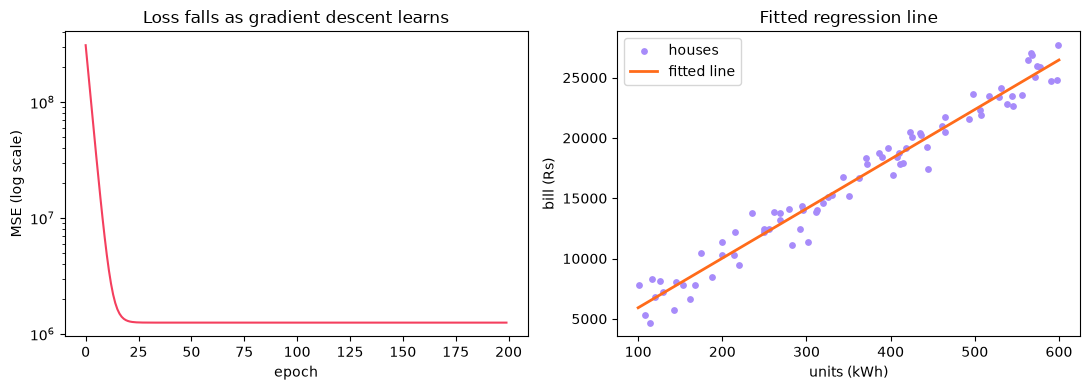

In [1]:
"""Linear regression with batch gradient descent, written from scratch with NumPy."""
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
units = rng.uniform(100, 600, 80)                     # kWh used in a month
bill = 1500 + 42 * units + rng.normal(0, 1200, 80)    # true rule: Rs 1500 fixed + Rs 42 per unit

# Scale x so gradient descent behaves (mean 0, sd 1)
mu, sd = units.mean(), units.std()
x = (units - mu) / sd

w, b, lr = 0.0, 0.0, 0.1
history = []
for epoch in range(200):
    y_hat = w * x + b
    err = bill - y_hat
    loss = np.mean(err ** 2)
    dw = -2 * np.mean(x * err)
    db = -2 * np.mean(err)
    w, b = w - lr * dw, b - lr * db
    history.append(loss)
    if epoch in (0, 1, 5, 20, 50, 199):
        print(f"epoch {epoch:>3}: MSE = {loss:>14,.0f}  w = {w:8.1f}  b = {b:8.1f}")

# Convert back to the original units: bill = b0 + slope * units
slope = w / sd
b0 = b - slope * mu
print(f"\nlearned rule: bill = {b0:.0f} + {slope:.2f} x units   (true: 1500 + 42 x units)")
print(f"predicted bill for 350 units: Rs {b0 + slope * 350:,.0f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history, color="#F43F5E"); ax[0].set_yscale("log")
ax[0].set_title("Loss falls as gradient descent learns"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("MSE (log scale)")
ax[1].scatter(units, bill, s=15, color="#A78BFA", label="houses")
grid = np.linspace(100, 600, 50)
ax[1].plot(grid, b0 + slope * grid, color="#FF6B1A", lw=2, label="fitted line")
ax[1].set_title("Fitted regression line"); ax[1].set_xlabel("units (kWh)"); ax[1].set_ylabel("bill (Rs)"); ax[1].legend()
fig.tight_layout(); fig.savefig("session-02_gradient_descent.png", dpi=110); plt.show()

### Example 2 · Intermediate: the learning rate and scikit-learn

In [2]:
"""Effect of the learning rate, and the same model in scikit-learn (closed form and SGD)."""
import numpy as np
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

rng = np.random.default_rng(0)
units = rng.uniform(100, 600, 80)
bill = 1500 + 42 * units + rng.normal(0, 1200, 80)
x = (units - units.mean()) / units.std()

def train(lr, epochs=50):
    w = b = 0.0
    for _ in range(epochs):
        err = bill - (w * x + b)
        w += lr * 2 * np.mean(x * err); b += lr * 2 * np.mean(err)
    return np.mean((bill - (w * x + b)) ** 2)

for lr in [0.001, 0.01, 0.1, 0.5, 1.05]:
    print(f"learning rate {lr:<6} -> MSE after 50 epochs: {train(lr):,.0f}")

X = units.reshape(-1, 1)                         # scikit-learn wants a 2-D X
ols = LinearRegression().fit(X, bill)
sgd = make_pipeline(StandardScaler(), SGDRegressor(max_iter=1000, random_state=0)).fit(X, bill)
print(f"\nLinearRegression (exact least squares): bill = {ols.intercept_:.0f} + {ols.coef_[0]:.2f} x units")
print(f"SGDRegressor prediction for 350 units: Rs {sgd.predict([[350]])[0]:,.0f}")
print(f"LinearRegression prediction for 350  : Rs {ols.predict([[350]])[0]:,.0f}")

learning rate 0.001  -> MSE after 50 epochs: 253,249,869
learning rate 0.01   -> MSE after 50 epochs: 42,076,661
learning rate 0.1    -> MSE after 50 epochs: 1,248,891
learning rate 0.5    -> MSE after 50 epochs: 1,248,891
learning rate 1.05   -> MSE after 50 epochs: 4,242,450,092,888

LinearRegression (exact least squares): bill = 1810 + 41.09 x units
SGDRegressor prediction for 350 units: Rs 16,192
LinearRegression prediction for 350  : Rs 16,191


### Example 3 · Intermediate: KNN from scratch, then choosing k

In [3]:
"""KNN: a from-scratch classifier, then scikit-learn with scaling and a search for the best k."""
import numpy as np
from collections import Counter
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

def knn_predict(X_train, y_train, x, k=3):
    """Return the majority label among the k nearest training points."""
    dist = np.sqrt(((X_train - x) ** 2).sum(axis=1))     # Euclidean distance to every point
    nearest = np.argsort(dist)[:k]
    return Counter(y_train[nearest]).most_common(1)[0][0]

# Tiny fruit example: [weight g, sweetness 1-10] -> 0 = lemon, 1 = orange
X_fruit = np.array([[120, 2], [130, 3], [110, 2], [150, 7], [170, 8], [160, 6]])
y_fruit = np.array([0, 0, 0, 1, 1, 1])
for fruit in ([125, 3], [165, 7], [140, 5]):
    label = knn_predict(X_fruit, y_fruit, np.array(fruit), k=3)
    print(f"fruit {fruit} -> {'orange' if label else 'lemon'}")

# Real data: breast tumour diagnosis, 30 features
X, y = load_breast_cancer(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=1, stratify=y)
raw = KNeighborsClassifier(5).fit(X_tr, y_tr).score(X_te, y_te)
scaled = make_pipeline(StandardScaler(), KNeighborsClassifier(5)).fit(X_tr, y_tr).score(X_te, y_te)
print(f"\nKNN k=5 accuracy without scaling: {raw:.3f}   with scaling: {scaled:.3f}")

print("\n k   5-fold CV accuracy")
for k in [1, 3, 5, 9, 15, 31, 75]:
    cv = cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(k)), X_tr, y_tr, cv=5).mean()
    print(f"{k:>2}   {cv:.3f}")

fruit [125, 3] -> lemon
fruit [165, 7] -> orange
fruit [140, 5] -> orange



KNN k=5 accuracy without scaling: 0.930   with scaling: 0.965

 k   5-fold CV accuracy
 1   0.955
 3   0.974
 5   0.972


 9   0.972
15   0.951


31   0.944
75   0.927


### Example 4 · Intermediate: Naive Bayes spam filter

In [4]:
"""Naive Bayes: a hand calculation with Bayes' theorem, then a MultinomialNB spam filter."""
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB

# --- Hand calculation: P(spam | message contains 'free') ---
p_spam, p_free_given_spam, p_free_given_ham = 0.30, 0.40, 0.02
p_free = p_free_given_spam * p_spam + p_free_given_ham * (1 - p_spam)
print(f"P(spam | 'free') = {p_free_given_spam * p_spam / p_free:.3f}")

# --- A small labelled SMS data set ---
texts = ["win a free prize now", "free entry claim your reward", "urgent you won cash call now",
         "claim free gift card today", "limited offer win money", "cheap loans approved click now",
         "are we meeting for lunch", "please send the lecture notes", "call me when you reach home",
         "the assignment is due tomorrow", "see you at the cricket match", "can you pick up milk today",
         "meeting moved to 3 pm", "happy birthday have a great day"]
labels = [1] * 6 + [0] * 8                                 # 1 = spam, 0 = ham

vec = CountVectorizer()
X = vec.fit_transform(texts)
nb = MultinomialNB(alpha=1.0).fit(X, labels)               # alpha=1 -> Laplace smoothing

new = ["free cash prize claim now", "notes for tomorrow's lecture", "call now to win", "lunch today?"]
for msg, p in zip(new, nb.predict_proba(vec.transform(new))[:, 1]):
    print(f"{msg:<32} P(spam) = {p:.3f} -> {'SPAM' if p >= 0.5 else 'ham'}")

# Most 'spammy' words: largest log P(word|spam) - log P(word|ham)
import numpy as np
diff = nb.feature_log_prob_[1] - nb.feature_log_prob_[0]
words = np.array(vec.get_feature_names_out())
print("\nmost spam-indicative words:", list(words[np.argsort(diff)[-6:][::-1]]))

P(spam | 'free') = 0.896
free cash prize claim now        P(spam) = 0.997 -> SPAM
notes for tomorrow's lecture     P(spam) = 0.076 -> ham
call now to win                  P(spam) = 0.888 -> SPAM
lunch today?                     P(spam) = 0.332 -> ham

most spam-indicative words: ['free', 'now', 'win', 'claim', 'your', 'prize']


### Example 5 · Advanced: logistic regression, the sigmoid and thresholds

from scratch : w = 1.62, b = -7.98, log-loss = 0.224
scikit-learn : w = 1.62, b = -7.98
odds ratio per extra hour: 5.03x
50% pass point: 4.9 hours
P(pass | 2 h) = 0.009
P(pass | 5 h) = 0.525
P(pass | 8 h) = 0.993

threshold  TN  FP  FN  TP
   0.3     79  16   5 100
   0.5     84  11   9  96
   0.7     90   5  15  90


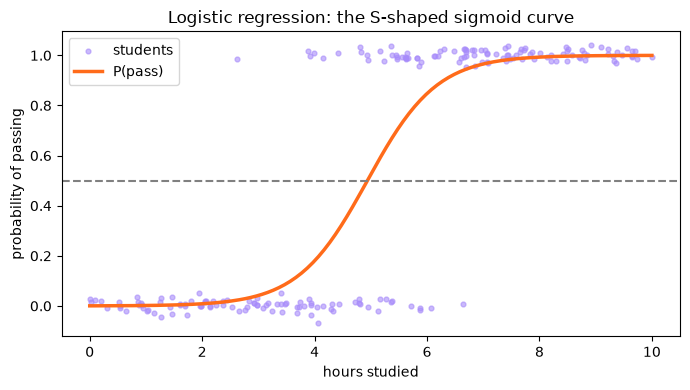

In [5]:
"""Logistic regression: sigmoid, from-scratch gradient descent, scikit-learn, odds ratios, thresholds."""
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

rng = np.random.default_rng(3)
# Students: hours studied -> passed (1) or failed (0)
hours = rng.uniform(0, 10, 200)
p_true = 1 / (1 + np.exp(-(1.2 * hours - 6)))
passed = (rng.random(200) < p_true).astype(int)

sigmoid = lambda z: 1 / (1 + np.exp(-z))

# From scratch: gradient descent on log-loss
w = b = 0.0
for _ in range(40000):                              # many small steps: hours are not scaled
    p = sigmoid(w * hours + b)
    w -= 0.1 * np.mean((p - passed) * hours)
    b -= 0.1 * np.mean(p - passed)
loss = -np.mean(passed * np.log(p) + (1 - passed) * np.log(1 - p))
print(f"from scratch : w = {w:.2f}, b = {b:.2f}, log-loss = {loss:.3f}")

clf = LogisticRegression(C=1e6).fit(hours.reshape(-1, 1), passed)      # huge C = almost no regularisation
print(f"scikit-learn : w = {clf.coef_[0][0]:.2f}, b = {clf.intercept_[0]:.2f}")
print(f"odds ratio per extra hour: {np.exp(clf.coef_[0][0]):.2f}x")
print(f"50% pass point: {-clf.intercept_[0] / clf.coef_[0][0]:.1f} hours")
for h in [2, 5, 8]:
    print(f"P(pass | {h} h) = {clf.predict_proba([[h]])[0, 1]:.3f}")

probs = clf.predict_proba(hours.reshape(-1, 1))[:, 1]
print("\nthreshold  TN  FP  FN  TP")
for t in [0.3, 0.5, 0.7]:
    tn, fp, fn, tp = confusion_matrix(passed, (probs >= t).astype(int)).ravel()
    print(f"   {t:.1f}    {tn:>3} {fp:>3} {fn:>3} {tp:>3}")

grid = np.linspace(0, 10, 200)
plt.figure(figsize=(7, 4))
plt.scatter(hours, passed + rng.normal(0, .02, 200), s=12, alpha=.6, color="#A78BFA", label="students")
plt.plot(grid, clf.predict_proba(grid.reshape(-1, 1))[:, 1], color="#FF6B1A", lw=2.5, label="P(pass)")
plt.axhline(0.5, ls="--", color="grey"); plt.xlabel("hours studied"); plt.ylabel("probability of passing")
plt.title("Logistic regression: the S-shaped sigmoid curve"); plt.legend()
plt.tight_layout(); plt.savefig("session-02_logistic_sigmoid.png", dpi=110); plt.show()

### 🏙️ Real-life data problem: predicting loan default

In [6]:
"""Real-life problem: compare three classifiers for loan default and pick a cost-optimal threshold."""
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix

rng = np.random.default_rng(11)
n = 3000
df = pd.DataFrame({
    "monthly_income_k": rng.lognormal(4.0, 0.45, n).round(1),      # thousand Rs
    "loan_amount_k": rng.uniform(20, 300, n).round(0),
    "existing_loans": rng.poisson(1.0, n),
    "years_employed": rng.exponential(4, n).round(1),
    "late_payments_12m": rng.poisson(0.6, n),
})
z = (-2.2 + 0.012 * df.loan_amount_k - 0.025 * df.monthly_income_k + 0.45 * df.existing_loans
     - 0.15 * df.years_employed + 0.7 * df.late_payments_12m)
df["default"] = (rng.random(n) < 1 / (1 + np.exp(-z))).astype(int)
print("default rate:", round(df["default"].mean(), 3))

X, y = df.drop(columns="default"), df["default"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
models = {"KNN (k=25)": make_pipeline(StandardScaler(), KNeighborsClassifier(25)),
          "Gaussian NB": GaussianNB(),
          "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression())}
print(f"\n{'model':<22}{'accuracy':>9}{'ROC AUC':>9}")
for name, m in models.items():
    m.fit(X_tr, y_tr)
    p = m.predict_proba(X_te)[:, 1]
    print(f"{name:<22}{accuracy_score(y_te, p >= .5):>9.3f}{roc_auc_score(y_te, p):>9.3f}")

# Pick the threshold with the lowest business cost
lr = models["Logistic regression"]; p = lr.predict_proba(X_te)[:, 1]
COST_FN, COST_FP = 80_000, 2_000
print("\nthreshold  missed defaulters  extra reviews   total cost (Rs)")
best = None
for t in [0.5, 0.4, 0.3, 0.2, 0.1, 0.05, 0.03, 0.02, 0.01]:
    tn, fp, fn, tp = confusion_matrix(y_te, p >= t).ravel()
    cost = fn * COST_FN + fp * COST_FP
    best = min(best or (cost, t), (cost, t))
    print(f"   {t:<5}        {fn:>4}             {fp:>4}       {cost:>12,}")
print(f"\nbest threshold: {best[1]}  (cost Rs {best[0]:,})")
print(f"theory: flag when p > C_FP / (C_FP + C_FN) = {COST_FP / (COST_FP + COST_FN):.3f}")

coefs = pd.Series(lr[-1].coef_[0], index=X.columns).sort_values()
print("\nstandardised coefficients (positive = raises default risk):\n", coefs.round(2).to_string())

default rate: 0.239

model                  accuracy  ROC AUC
KNN (k=25)                0.780    0.761
Gaussian NB               0.786    0.769
Logistic regression       0.798    0.795

threshold  missed defaulters  extra reviews   total cost (Rs)
   0.5           141               41         11,362,000
   0.4           110               80          8,960,000
   0.3            79              142          6,604,000
   0.2            40              237          3,674,000
   0.1            19              398          2,316,000
   0.05            7              544          1,648,000
   0.03            4              616          1,552,000
   0.02            3              642          1,524,000
   0.01            1              668          1,416,000

best threshold: 0.01  (cost Rs 1,416,000)
theory: flag when p > C_FP / (C_FP + C_FN) = 0.024

standardised coefficients (positive = raises default risk):
 monthly_income_k    -0.78
years_employed      -0.46
existing_loans       0.46
late_

### 🧩 Mini project: student pass predictor

In [7]:
"""Mini project: predict whether students pass, choose a model by CV, explain predictions."""
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report

rng = np.random.default_rng(5)
n = 600
students = pd.DataFrame({"study_hours": rng.uniform(0, 15, n), "attendance": rng.uniform(40, 100, n),
                         "assignments_done": rng.integers(0, 11, n), "past_gpa": rng.uniform(1.5, 4.0, n)})
z = -9 + 0.35 * students.study_hours + 0.05 * students.attendance + 0.25 * students.assignments_done + 0.9 * students.past_gpa
students["passed"] = (rng.random(n) < 1 / (1 + np.exp(-z))).astype(int)

X, y = students.drop(columns="passed"), students["passed"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
candidates = {"logistic": make_pipeline(StandardScaler(), LogisticRegression()),
              "knn": make_pipeline(StandardScaler(), KNeighborsClassifier(15))}
scores = {k: cross_val_score(m, X_tr, y_tr, cv=5).mean() for k, m in candidates.items()}
print("CV accuracy:", {k: round(float(v), 3) for k, v in scores.items()})
best_name = max(scores, key=scores.get)
model = candidates[best_name].fit(X_tr, y_tr)
print(f"chosen model: {best_name}\n")
print(classification_report(y_te, model.predict(X_te), target_names=["fail", "pass"]))

new = pd.DataFrame({"study_hours": [2, 8, 12], "attendance": [55, 80, 95],
                    "assignments_done": [3, 7, 10], "past_gpa": [2.0, 2.9, 3.6]})
coef = model[-1].coef_[0] if best_name == "logistic" else None
for i, row in new.iterrows():
    p = model.predict_proba(row.to_frame().T)[0, 1]
    msg = f"student {i + 1}: P(pass) = {p:.2f}"
    if coef is not None:
        contrib = model[0].transform(row.to_frame().T)[0] * coef
        msg += f" | biggest factor: {X.columns[np.argmax(np.abs(contrib))]}"
    print(msg)

CV accuracy: {'logistic': 0.773, 'knn': 0.773}
chosen model: logistic

              precision    recall  f1-score   support

        fail       0.85      0.69      0.77        59
        pass       0.82      0.92      0.87        91

    accuracy                           0.83       150
   macro avg       0.84      0.81      0.82       150
weighted avg       0.84      0.83      0.83       150

student 1: P(pass) = 0.06 | biggest factor: study_hours
student 2: P(pass) = 0.88 | biggest factor: attendance
student 3: P(pass) = 0.99 | biggest factor: study_hours
